In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
# glac = pd.read_parquet("/wolke_scratch/dnikolo/GTE_Validation/Pixel_py_pixel_with_cth/CTH_included/Results/Agg_03_glaciations_20070501.0000_20070512.0000.parquet")
# cloud = pd.read_parquet("/wolke_scratch/dnikolo/GTE_Validation/Pixel_py_pixel_with_cth/CTH_included/Results/Agg_03_clouds_20070501.0000_20070512.0000.parquet")

In [2]:
folder = Path("/wolke_scratch/dnikolo/GTE_Validation/Pixel_py_pixel_with_cth/Results/")

cloud_files = sorted(folder.glob("*clouds*.parquet"))  # case-sensitive
# If you want case-insensitive match:
# cloud_files = sorted([f for f in folder.glob("*.parquet") if "df_clouds" in f.name.lower()])

dfs = [pd.read_parquet(f) for f in cloud_files]
df_clouds = pd.concat(dfs, ignore_index=True, copy=False)

glac_files = sorted(folder.glob("*glac*.parquet"))  # case-sensitive
# If you want case-insensitive match:
# cloud_files = sorted([f for f in folder.glob("*.parquet") if "df_clouds" in f.name.lower()])

dfs = [pd.read_parquet(f) for f in glac_files]
df_glac = pd.concat(dfs, ignore_index=True, copy=False)


KeyboardInterrupt: 

In [35]:
def get_mean_dd_ice_frac_hist(row):
    if_hist = row["dd_ice_frac_hist"]
    if (np.isnan(if_hist) | (if_hist==-1)).all():
        return np.nan
    return if_hist[~np.isnan(if_hist)].mean()
def get_mean_dd_ice_frac_dev(row):
    if_hist_dev = row["dd_ice_frac_dev_hist"]
    if (np.isnan(if_hist_dev) | (if_hist_dev==-99)).all():
        return np.nan
    if_hist_dev = if_hist_dev[~np.isnan(if_hist_dev)]
    if_hist_dev = if_hist_dev[if_hist_dev >-99]
    if if_hist_dev.size>0:
        return if_hist_dev.mean()
    else:
        return np.nan

def get_if_dev_same_cloud(row):
    try:
        if_hist_dev = row["dd_ice_frac_dev_hist"]
        if (np.isnan(if_hist_dev) | (if_hist_dev==-99)).all():
            return np.nan
        points_of_interest = row["dd_cth_hist"] > 0
        if type(row["cth_hist"]) == float:
            return np.nan 
        cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["dd_cth_hist"][points_of_interest])
        if cth_deviations.size == 0:
            return np.nan
        mean_height_dev = cth_deviations.mean()  
        if mean_height_dev > 1000:
            return np.nan     
        if_hist_dev = if_hist_dev[~np.isnan(if_hist_dev)]
        if_hist_dev = if_hist_dev[if_hist_dev >-99]
        if if_hist_dev.size>0:
            return if_hist_dev.mean()
        else:
            return np.nan
    except Exception as e:
        print(f"Error processing row: {e} {row['cth_hist']}")
        return np.nan
N=1
def get_if_dev_glac_peak_same_cloud(row):
    if_hist = row["dd_ice_frac_hist"]
    points_of_interest = row["dd_cth_hist"] > 0
    if type(row["cth_hist"]) == float:
            N+=1
            return np.nan 
    cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["dd_cth_hist"][points_of_interest])
    if cth_deviations.size == 0:
        return np.nan
    mean_height_dev = cth_deviations.mean()  
    if mean_height_dev > 1000:
        return np.nan
    peak_value = if_hist[row["Glac_peak_ind"]]   
    if peak_value >=0:
        return peak_value
    else:
        return np.nan


In [36]:
df_glac["dd_mean_if"] = df_glac.apply(get_mean_dd_ice_frac_hist, axis=1)
df_glac["dd_mean_if_dev"] = df_glac.apply(get_if_dev_same_cloud, axis=1)
df_glac["dd_peak_if"] = df_glac.apply(get_if_dev_glac_peak_same_cloud, axis=1)
df_clouds["dd_mean_if"] = df_clouds.apply(get_mean_dd_ice_frac_hist, axis=1)
df_clouds["dd_mean_if_dev"] = df_clouds.apply(get_if_dev_same_cloud, axis=1)
valid_glac= df_glac[~df_glac["dd_mean_if_dev"].isna()]
valid_cloud= df_clouds[~df_clouds["dd_mean_if_dev"].isna()]

In [ ]:

# glac["dd_mean_if"] = glac.apply(get_mean_dd_ice_frac_hist, axis=1)
# glac["dd_mean_if_dev"] = glac.apply(get_if_dev_same_cloud, axis=1)
# glac["dd_peak_if"] = glac.apply(get_if_dev_glac_peak_same_cloud, axis=1)
# df_clouds["dd_mean_if"] = df_clouds.apply(get_mean_dd_ice_frac_hist, axis=1)
# df_clouds["dd_mean_if_dev"] = df_clouds.apply(get_if_dev_same_cloud, axis=1)
# valid_glac= glac[~glac["dd_mean_if_dev"].isna()]
# valid_cloud= df_clouds[~df_clouds["dd_mean_if_dev"].isna()]


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


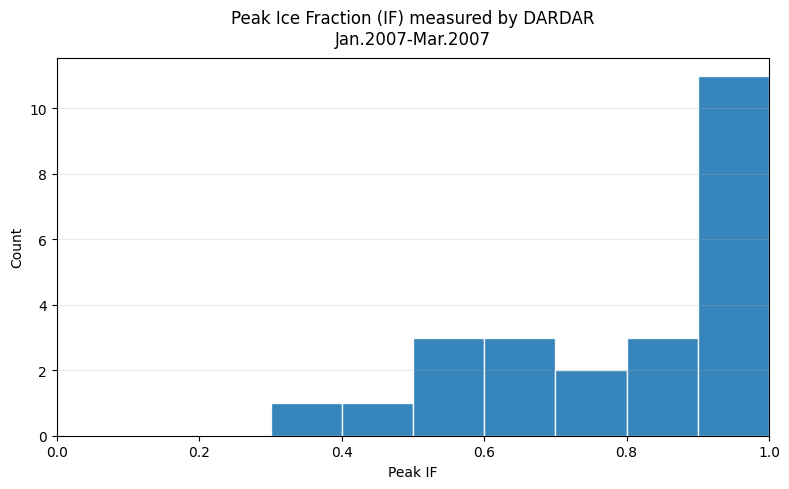

In [54]:
import matplotlib.pyplot as plt

s = valid_glac["dd_peak_if"].dropna()
med = s.median()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(s, bins=10, edgecolor="white", linewidth=1, alpha=0.9, range = (0,1))
# ax.axvline(med, linestyle="--", linewidth=2, label=f"Median = {med:.3g}", color="black")

ax.set_title("Peak Ice Fraction (IF) measured by DARDAR\nJan.2007-Mar.2007", pad=10)
ax.set_xlabel("Peak IF")
ax.set_ylabel("Count")
ax.grid(True, axis="y", alpha=0.25)
ax.legend(frameon=False)
ax.set_xlim(0,1)
plt.tight_layout()
plt.show()

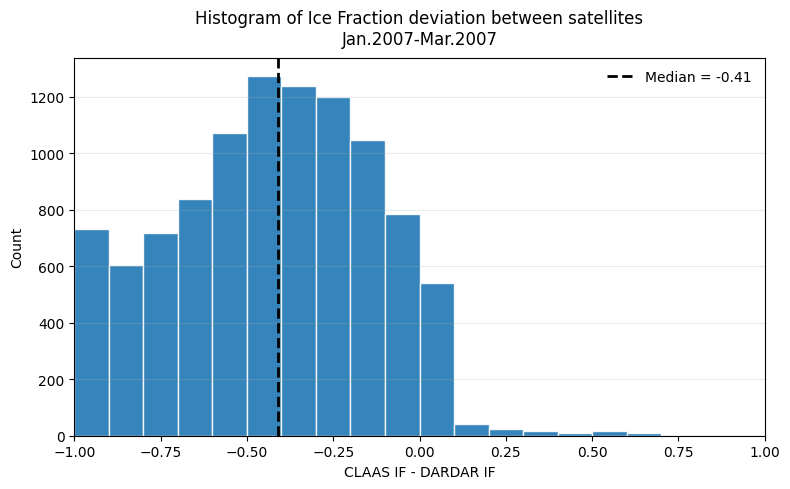

In [55]:
import matplotlib.pyplot as plt

s = valid_cloud["dd_mean_if_dev"].dropna()
med = s.median()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(s, bins=20, edgecolor="white", linewidth=1, alpha=0.9, range = (-1,1))
ax.axvline(med, linestyle="--", linewidth=2, label=f"Median = {med:.3g}", color="black")

ax.set_title("Histogram of Ice Fraction deviation between satellites\nJan.2007-Mar.2007", pad=10)
ax.set_xlabel("CLAAS IF - DARDAR IF")
ax.set_ylabel("Count")
ax.grid(True, axis="y", alpha=0.25)
ax.legend(frameon=False)
ax.set_xlim(-1,1)
plt.tight_layout()
plt.show()

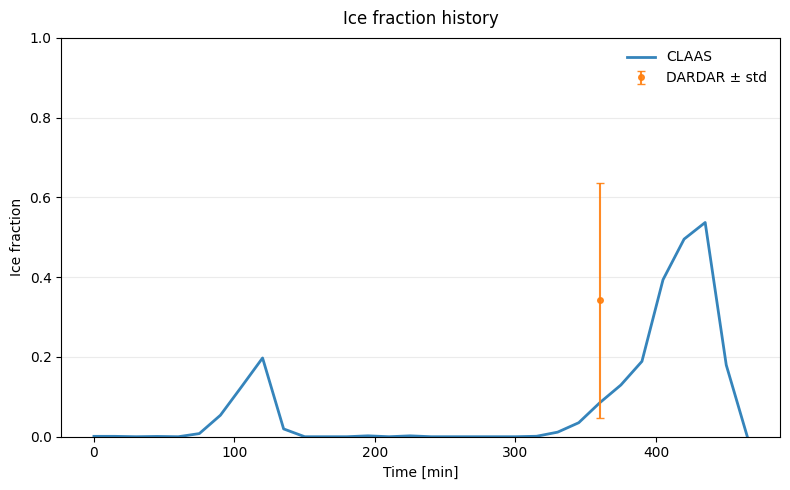

In [105]:
import numpy as np
import matplotlib.pyplot as plt

test_cloud = valid_glac.iloc[2]
claas_if_hist = test_cloud["ice_frac_hist"]
dd_if_hist    = test_cloud["dd_ice_frac_hist"]
dd_if_std_hist = test_cloud["dd_ice_frac_std_hist"].copy()

# clean std + validity mask
dd_if_std_hist = np.array(dd_if_std_hist, dtype=float)
dd_if_std_hist[dd_if_std_hist < 0] = np.nan

claas_if_hist = np.array(claas_if_hist, dtype=float)
dd_if_hist    = np.array(dd_if_hist, dtype=float)

valid_pixels = ~np.isnan(claas_if_hist) & ~np.isnan(dd_if_hist) & (dd_if_hist > -1)

x = np.arange(len(claas_if_hist))*15

fig, ax = plt.subplots(figsize=(8, 5))

# line (CLAAS)
ax.plot(x, claas_if_hist, linewidth=2, alpha=0.9, label="CLAAS")

# points + errorbars (DD), only for valid pixels
ax.errorbar(
    x[valid_pixels],
    dd_if_hist[valid_pixels],
    yerr=dd_if_std_hist[valid_pixels],
    fmt="o",
    linestyle="none",
    markersize=4,
    capsize=3,
    linewidth=1.5,
    alpha=0.9,
    label="DARDAR ± std",
)

ax.set_title("Ice fraction history", pad=10)
ax.set_xlabel("Time [min]")
ax.set_ylabel("Ice fraction")
ax.set_ylim(0, 1)

ax.grid(True, axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [10]:
test_cloud.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'dd_ice_frac_hist', 'dd_ice_frac_std_hist', 'dd_ice_frac_dev_hist',
       'dd_pix_claas_if_hist', 'dd_pix_claas_if_std_hist', 'dd_cth_hist',
       'dd

In [14]:
test_cloud["dd_cth_hist"]

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,  5.11168466e+03,
       -1.00000000e+00, -

In [18]:
points_of_interest = test_cloud["dd_cth_hist"] > 0
(np.abs(test_cloud["cth_hist"][points_of_interest] - test_cloud["dd_cth_hist"][points_of_interest])).mean()

727.5957948634059

In [27]:
dd_if_std_hist

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.09222585, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        ])

In [21]:
valid_glac[valid_glac.dd_mean_if>=0]["dd_ice_frac_dev_hist"]

45      [nan, nan, nan, nan, -0.5239448609869354, nan,...
68      [nan, nan, nan, nan, nan, nan, nan, nan, nan, ...
119     [nan, nan, nan, nan, nan, nan, nan, nan, nan, ...
120     [nan, nan, nan, nan, nan, nan, nan, nan, nan, ...
146            [nan, -0.35225769877433777, nan, nan, nan]
                              ...                        
5201    [nan, nan, nan, nan, nan, nan, nan, nan, nan, ...
5293    [nan, nan, nan, nan, nan, nan, nan, nan, nan, ...
5301    [nan, nan, nan, nan, nan, -0.36952926030104183...
5367    [nan, nan, nan, nan, -0.519576273452152, nan, ...
5373    [nan, nan, -0.8315528333187103, nan, nan, nan,...
Name: dd_ice_frac_dev_hist, Length: 256, dtype: object